# Perception–Reasoning Counterfactual Routing (PRCR)
### Diagnosing and Recovering Vision-Language Model Errors at Inference Time

**Kaggle notebook: feature extraction → router training → testing → analysis**

**Setup (Kaggle):** Accelerator = GPU (T4 or P100), *Internet = On* (data and model are pulled from Hugging Face).

**Pipeline**
1. **Part A (GPU, slow):** run a frozen VLM (Qwen2-VL-2B-Instruct) on ScienceQA (train/val/test), POPE and MathVista (test only). For every sample we record the baseline answer distribution, 5 counterfactual probes (3 visual, 2 textual), and 3 repair answers (visual re-grounding, reasoning refinement, both). Everything is cached to disk, so a crashed or restarted session resumes where it stopped.
2. **Part B (CPU, fast):** derive diagnosis labels (OK / PERC / REAS / MIXED / UNRES), train and calibrate the router, compare with baselines, and produce tables and figures for the paper.

**Honest notes**
- Diagnosis labels are *oracle labels* derived from which repair fixes a wrong baseline answer (Methodology, "Diagnosis Labels from Counterfactual Repair"). They are operational labels, not human annotation.
- A fifth class, **OK** (baseline already correct), is added so the router learns when *not* to intervene. Add it to the paper's label set.
- All questions are converted to multiple choice (POPE becomes A. Yes / B. No), so the answer distribution is the softmax over option-letter logits.

## 0. Install and configuration

In [1]:
!pip install -q "transformers>=4.45" accelerate datasets scikit-learn seaborn pillow tqdm

In [2]:
import os, sys, time, json, pickle, random, math, warnings, glob
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")

WORK  = "/kaggle/working" if os.path.exists("/kaggle/working") else "./work"
CACHE = f"{WORK}/cache"
RES   = f"{WORK}/results"
os.makedirs(CACHE, exist_ok=True); os.makedirs(RES, exist_ok=True)

CFG = dict(
    MODEL_ID    = "Qwen/Qwen2-VL-2B-Instruct",
    SEED        = 42,
    # number of samples per split. Raise for the final paper run, lower if time is short.
    N_TRAIN     = 1200,   # ScienceQA train  -> router training
    N_VAL       = 300,    # ScienceQA val    -> model selection, temperature, thresholds
    N_TEST_SQA  = 300,    # ScienceQA test   -> in-domain test
    N_TEST_POPE = 300,    # POPE             -> cross-benchmark (perception / hallucination)
    N_TEST_MV   = 300,    # MathVista testmini, multiple-choice only -> cross-benchmark (reasoning)
    MIN_PIXELS  = 64*28*28,
    MAX_PIXELS  = 256*28*28,   # lowers visual tokens so a T4 stays fast
    CAP_TOKENS  = 96,
    COT_TOKENS  = 128,
    QUICK_DEBUG = False,       # True = 16 samples per split to test the whole notebook in minutes
)
if CFG["QUICK_DEBUG"]:
    for k in ["N_TRAIN","N_VAL","N_TEST_SQA","N_TEST_POPE","N_TEST_MV"]:
        CFG[k] = 16

random.seed(CFG["SEED"]); np.random.seed(CFG["SEED"])
print(json.dumps(CFG, indent=1))

{
 "MODEL_ID": "Qwen/Qwen2-VL-2B-Instruct",
 "SEED": 42,
 "N_TRAIN": 1200,
 "N_VAL": 300,
 "N_TEST_SQA": 300,
 "N_TEST_POPE": 300,
 "N_TEST_MV": 300,
 "MIN_PIXELS": 50176,
 "MAX_PIXELS": 200704,
 "CAP_TOKENS": 96,
 "COT_TOKENS": 128,
 "QUICK_DEBUG": false
}


## 1. Load the frozen VLM

In [3]:
import torch
from PIL import Image, ImageFilter
from tqdm.auto import tqdm
from transformers import Qwen2VLForConditionalGeneration, AutoProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "")

def load_model(dtype):
    m = Qwen2VLForConditionalGeneration.from_pretrained(
        CFG["MODEL_ID"], torch_dtype=dtype, attn_implementation="sdpa").to(device).eval()
    return m

processor = AutoProcessor.from_pretrained(
    CFG["MODEL_ID"], min_pixels=CFG["MIN_PIXELS"], max_pixels=CFG["MAX_PIXELS"])
tokenizer = processor.tokenizer
model = load_model(torch.float16 if device == "cuda" else torch.float32)

LETTERS = list("ABCDEFGH")
def _ids(s):
    out = set()
    for v in (s, " " + s):
        t = tokenizer.encode(v, add_special_tokens=False)
        out.add(t[-1])
    return sorted(out)
CAND = [_ids(l) for l in LETTERS]   # each option letter -> its token ids (with / without leading space)

device: cuda Tesla T4


preprocessor_config.json:   0%|          | 0.00/347 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

... (3 outputs left out)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

### 1.1 Model I/O helpers (option probabilities and text generation)

In [4]:
def build_inputs(img, prompt, prefix=""):
    content = ([{"type": "image"}] if img is not None else []) + [{"type": "text", "text": prompt}]
    msgs = [{"role": "user", "content": content}]
    text = processor.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True) + prefix
    inputs = processor(text=[text], images=[img] if img is not None else None,
                       return_tensors="pt", padding=False)
    return {k: v.to(device) for k, v in inputs.items()}

@torch.inference_mode()
def option_probs(img, prompt, n_opts, prefix=""):
    """Softmax over the option-letter logits at the next-token position."""
    inp = build_inputs(img, prompt, prefix)
    logits = model(**inp).logits[0, -1].float()
    lp = torch.log_softmax(logits, -1)
    sc = torch.stack([torch.logsumexp(lp[CAND[i]], 0) for i in range(n_opts)])
    p = torch.softmax(sc, 0).cpu().numpy().astype(np.float64)
    if not np.all(np.isfinite(p)): raise FloatingPointError("non-finite probabilities")
    return p

@torch.inference_mode()
def gen_text(img, prompt, max_new_tokens):
    inp = build_inputs(img, prompt)
    out = model.generate(**inp, max_new_tokens=max_new_tokens, do_sample=False)
    new = out[:, inp["input_ids"].shape[1]:]
    return processor.batch_decode(new, skip_special_tokens=True)[0].strip()

def fmt_options(choices):
    return "\n".join(f"{LETTERS[i]}. {c}" for i, c in enumerate(choices))

def base_prompt(q, choices, style=0):
    if style == 0:
        return (f"Question: {q}\nOptions:\n{fmt_options(choices)}\n"
                "Answer with the letter of the correct option only.")
    return (f"Carefully consider the question below.\n{q}\nChoices:\n{fmt_options(choices)}\n"
            "Reply with a single letter.")

CAP_PROMPT   = ("Describe this image in detail. List the objects, their attributes, counts, any text, "
                "and their spatial relations.")
COT_SUFFIX   = "\nThink step by step in at most three short sentences, then give the final answer."
FINAL_PREFIX = "\nFinal answer (letter only): "

# sanity check: make sure fp16 gives finite outputs, else fall back to fp32 (known Qwen2-VL/T4 issue)
_toy = Image.new("RGB", (224, 224), (200, 30, 30))
try:
    _p = option_probs(_toy, base_prompt("What colour is the image?", ["red", "blue"]), 2)
    print("sanity probs:", _p)
except Exception as e:
    print("fp16 failed (", repr(e)[:80], ") -> reloading in fp32")
    del model; torch.cuda.empty_cache()
    model = load_model(torch.float32)
    print("sanity probs:", option_probs(_toy, base_prompt("What colour is the image?", ["red", "blue"]), 2))

sanity probs: [0.52341866 0.47658136]


## 2. Datasets
- **ScienceQA** (`derek-thomas/ScienceQA`): train/val/test, image questions only. Used to train and select the router; test split is in-domain.
- **POPE** (`lmms-lab/POPE`): object-hallucination yes/no questions, converted to A/B. Cross-benchmark, perception-heavy.
- **MathVista** (`AI4Math/MathVista`, `testmini`, multiple-choice only). Cross-benchmark, reasoning-heavy.

No test benchmark is used for training.

In [5]:
from datasets import load_dataset

def _prep_img(im):
    im = im.convert("RGB")
    w, h = im.size
    if min(w, h) < 56:                       # Qwen2-VL needs >= 28 px per side; keep a safety margin
        s = 56 / min(w, h); im = im.resize((max(56, int(w*s)), max(56, int(h*s))))
    return im

def load_sqa(split, n, seed):
    ds = load_dataset("derek-thomas/ScienceQA", split=split, streaming=True)
    ds = ds.filter(lambda x: x["image"] is not None).shuffle(seed=seed, buffer_size=2000).take(n)
    out = []
    for x in ds:
        ch = list(x["choices"])
        if not (2 <= len(ch) <= 8): continue
        q = x["question"] + (f"\nContext: {x['hint']}" if x.get("hint") else "")
        out.append(dict(img=_prep_img(x["image"]), q=q, choices=ch, label=int(x["answer"])))
    return out

def load_pope(n, seed):
    ds = load_dataset("lmms-lab/POPE", split="test")
    idx = np.random.RandomState(seed).permutation(len(ds))[:n]
    out = []
    for i in idx:
        x = ds[int(i)]
        lab = 0 if str(x["answer"]).strip().lower().startswith("yes") else 1
        out.append(dict(img=_prep_img(x["image"]), q=x["question"], choices=["Yes", "No"], label=lab))
    return out

def load_mathvista(n, seed):
    ds = load_dataset("AI4Math/MathVista", split="testmini")
    qt = ds["question_type"]
    idx = [i for i, t in enumerate(qt) if t == "multi_choice"]
    idx = list(np.random.RandomState(seed).permutation(idx))
    out = []
    for i in idx:
        x = ds[int(i)]
        ch = list(x["choices"]) if x["choices"] else []
        if not (2 <= len(ch) <= 8) or x["answer"] not in ch: continue
        im = x.get("decoded_image") or x.get("image")
        if im is None or isinstance(im, str): continue
        out.append(dict(img=_prep_img(im), q=x["question"], choices=ch, label=ch.index(x["answer"])))
        if len(out) >= n: break
    return out

DATA = {}
DATA["sqa_train"] = load_sqa("train",      CFG["N_TRAIN"],     CFG["SEED"])
DATA["sqa_val"]   = load_sqa("validation", CFG["N_VAL"],       CFG["SEED"] + 1)
DATA["sqa_test"]  = load_sqa("test",       CFG["N_TEST_SQA"],  CFG["SEED"] + 2)
DATA["pope_test"] = load_pope(CFG["N_TEST_POPE"],              CFG["SEED"] + 3)
DATA["mv_test"]   = load_mathvista(CFG["N_TEST_MV"],           CFG["SEED"] + 4)
for k, v in DATA.items():
    print(f"{k:10s} n={len(v):5d}  options/question={np.mean([len(s['choices']) for s in v]):.2f}")

README.md:   0%|          | 0.00/10.3k [00:00<?, ?B/s]

README.md:   0%|          | 0.00/2.16k [00:00<?, ?B/s]

data/test-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B / 85.0MB            

data/test-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/test-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B / 85.0MB            

data/test-00001-of-00003.parquet: downloading bytes:           |  0.00B            

... (9 outputs left out)

data/test-00001-of-00002-6a611c71596db30(…): downloading bytes:           |  0.00B            

Generating testmini split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5141 [00:00<?, ? examples/s]

sqa_train  n= 1200  options/question=3.10
sqa_val    n=  300  options/question=3.08
sqa_test   n=  300  options/question=3.08
pope_test  n=  300  options/question=2.00
mv_test    n=  300  options/question=3.46


## 3. Counterfactual probes, repairs and caching

For every sample the extractor computes:

| Step | What it does | Used for |
|---|---|---|
| baseline | answer distribution `p0` from (image, question) | confidence features |
| **visual probes** | blur, centre-zoom crop, no-image | perception-side sensitivity `s_v`, `g_v` |
| **textual probes** | reversed option order, paraphrased instruction | reasoning-side sensitivity `s_r`, `g_r` |
| **V-repair** | the model captions the image, then answers with the caption | perception recovery |
| **R-repair** | short step-by-step rationale, then final letter | reasoning recovery |
| **V+R repair** | caption and rationale together | mixed recovery |

Jensen–Shannon divergence between `p0` and each probe distribution is normalised to [0, 1].

In [7]:
LN2 = np.log(2.0)
def js(p, q):
    m = 0.5 * (p + q)
    kl = lambda a, b: float(np.sum(a * np.log((a + 1e-12) / (b + 1e-12))))
    return (0.5 * kl(p, m) + 0.5 * kl(q, m)) / LN2

V_PROBES, T_PROBES = ["blur", "crop", "noimg"], ["shuf", "para"]

def make_features(p0, probes):
    n = len(p0); a0 = int(np.argmax(p0)); srt = np.sort(p0)[::-1]
    f = dict(c0=float(srt[0]), H0=float(-(p0 * np.log(p0 + 1e-12)).sum() / np.log(n)),
             margin=float(srt[0] - srt[1]))
    for k in V_PROBES + T_PROBES:
        f["js_" + k] = js(p0, probes[k]); f["ag_" + k] = float(np.argmax(probes[k]) == a0)
    f["s_v"] = float(np.mean([f["js_" + k] for k in V_PROBES])); f["g_v"] = float(np.mean([f["ag_" + k] for k in V_PROBES]))
    f["s_r"] = float(np.mean([f["js_" + k] for k in T_PROBES])); f["g_r"] = float(np.mean([f["ag_" + k] for k in T_PROBES]))
    return f

def _now():
    if device == "cuda": torch.cuda.synchronize()
    return time.perf_counter()

def extract(s):
    img, q, ch = s["img"], s["q"], s["choices"]; n = len(ch)
    bp = base_prompt(q, ch, 0)
    t = _now(); p0 = option_probs(img, bp, n); t_base = _now() - t

    t = _now(); probes = {}
    probes["blur"]  = option_probs(img.filter(ImageFilter.GaussianBlur(radius=8)), bp, n)
    w, h = img.size; cw, chh = int(w * 0.6), int(h * 0.6); l, tp = (w - cw) // 2, (h - chh) // 2
    probes["crop"]  = option_probs(img.crop((l, tp, l + cw, tp + chh)).resize((w, h)), bp, n)
    probes["noimg"] = option_probs(None, bp, n)
    perm = list(range(n))[::-1]
    pp = option_probs(img, base_prompt(q, [ch[j] for j in perm], 0), n)
    ps = np.zeros(n)
    for j in range(n): ps[perm[j]] = pp[j]
    probes["shuf"] = ps
    probes["para"] = option_probs(img, base_prompt(q, ch, 1), n)
    t_probe = _now() - t

    t = _now(); cap = gen_text(img, CAP_PROMPT, CFG["CAP_TOKENS"]); t_cap = _now() - t
    cap_prefix = f"Image description (written by you): {cap}\n\n"

    t = _now(); pV = option_probs(img, cap_prefix + bp, n); t_V = t_cap + (_now() - t)

    t = _now(); cp = bp + COT_SUFFIX
    rat = gen_text(img, cp, CFG["COT_TOKENS"]); pR = option_probs(img, cp, n, prefix=rat + FINAL_PREFIX)
    t_R = _now() - t

    t = _now(); cp2 = cap_prefix + bp + COT_SUFFIX
    rat2 = gen_text(img, cp2, CFG["COT_TOKENS"]); pVR = option_probs(img, cp2, n, prefix=rat2 + FINAL_PREFIX)
    t_VR = t_cap + (_now() - t)

    return dict(p0=p0.tolist(), pV=pV.tolist(), pR=pR.tolist(), pVR=pVR.tolist(),
                f=make_features(p0, probes),
                t=dict(base=t_base, probe=t_probe, cap=t_cap, V=t_V, R=t_R, VR=t_VR),
                cap=cap[:300], rat=rat[:300])

def run_split(name, samples):
    path = f"{CACHE}/{name}.pkl"
    recs = pickle.load(open(path, "rb")) if os.path.exists(path) else []
    done = {r["idx"] for r in recs}
    fails = 0
    for i, s in enumerate(tqdm(samples, desc=name)):
        if i in done: continue
        try:
            r = extract(s)
        except Exception as e:
            fails += 1; print("skip", i, repr(e)[:120]); continue
        r.update(ds=name, idx=i, y=int(s["label"]), n=len(s["choices"]), q=s["q"][:160].replace("\n", " "))
        recs.append(r)
        if len(recs) % 25 == 0:
            pickle.dump(recs, open(path, "wb"))
        if len(recs) % 50 == 0 and device == "cuda": torch.cuda.empty_cache()
    pickle.dump(recs, open(path, "wb"))
    print(f"{name}: {len(recs)} records ({fails} skipped)")
    return recs



print("done")

done


### 3.1 Run extraction (this is the slow cell)
Run `QUICK_DEBUG = True` first to confirm everything works. Progress is saved every 25 samples. If Kaggle disconnects, re-run the notebook: finished samples are skipped automatically. Measure the speed on the first split and scale the `N_*` values to your time budget.

In [ ]:
t0 = time.time()
for name in ["sqa_val", "sqa_test", "pope_test", "mv_test", "sqa_train"]:   # small splits first
    run_split(name, DATA[name])
    print(f"elapsed {(time.time()-t0)/60:.1f} min")

sqa_val:   0%|          | 0/300 [00:00<?, ?it/s]

sqa_val: 300 records (0 skipped)
elapsed 49.5 min


sqa_test:   0%|          | 0/300 [00:00<?, ?it/s]

sqa_test: 300 records (0 skipped)
elapsed 97.6 min


pope_test:   0%|          | 0/300 [00:00<?, ?it/s]

pope_test: 300 records (0 skipped)
elapsed 127.4 min


mv_test:   0%|          | 0/300 [00:00<?, ?it/s]

mv_test: 300 records (0 skipped)
elapsed 178.9 min


sqa_train:   0%|          | 0/1200 [00:00<?, ?it/s]

In [14]:
# free the GPU before the analysis part (Part B only needs the cached files)
try:
    del model
    torch.cuda.empty_cache()
except Exception:
    pass
print(sorted(os.listdir(CACHE)))


print("done")

['mv_test.pkl', 'pope_test.pkl', 'sqa_test.pkl', 'sqa_train.pkl', 'sqa_val.pkl']
done


# Part B: Router training, testing and analysis
Part B only needs the cache files, so it can be re-run (or run on CPU) after a restart.

In [15]:
# PART-B
import os, json, pickle, glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
WORK  = "/kaggle/working" if os.path.exists("/kaggle/working") else "./work"
CACHE = f"{WORK}/cache"; RES = f"{WORK}/results"; os.makedirs(RES, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams["figure.dpi"] = 110

CLASSES   = ["OK", "PERC", "REAS", "MIXED", "UNRES"]
FEATS     = ["s_v", "s_r", "g_v", "g_r", "c0", "H0", "margin", "js_blur", "js_crop", "js_noimg", "js_shuf", "js_para"]
F_VISUAL  = ["s_v", "g_v", "js_blur", "js_crop", "js_noimg"]
F_TEXT    = ["s_r", "g_r", "js_shuf", "js_para"]
F_CONF    = ["c0", "H0", "margin"]
TEST_SETS = ["sqa_test", "pope_test", "mv_test"]
PRETTY    = {"sqa_test": "ScienceQA (in-domain)", "pope_test": "POPE", "mv_test": "MathVista-MC"}

def oracle_label(r):
    if r["base_ok"]: return "OK"
    v, rr, vr = r["V_ok"], r["R_ok"], r["VR_ok"]
    if v and not rr: return "PERC"
    if rr and not v: return "REAS"
    if v and rr:     return "MIXED"
    if vr:           return "MIXED"
    return "UNRES"

def load_df():
    rows = []
    for fn in sorted(glob.glob(f"{CACHE}/*.pkl")):
        for r in pickle.load(open(fn, "rb")):
            row = dict(ds=r["ds"], idx=r["idx"], y=r["y"], n=r["n"], q=r["q"], cap=r.get("cap", ""), rat=r.get("rat", ""))
            for k in ["p0", "pV", "pR", "pVR"]:
                row[k] = np.array(r[k]); row[k + "_pred"] = int(np.argmax(r[k]))
            row.update(r["f"]); row.update({"t_" + k: v for k, v in r["t"].items()})
            rows.append(row)
    d = pd.DataFrame(rows)
    d["base_ok"] = d.p0_pred == d.y
    d["V_ok"]  = d.pV_pred  == d.y
    d["R_ok"]  = d.pR_pred  == d.y
    d["VR_ok"] = d.pVR_pred == d.y
    d["label"] = d.apply(oracle_label, axis=1)
    return d

df = load_df()
tr, va = df[df.ds == "sqa_train"].reset_index(drop=True), df[df.ds == "sqa_val"].reset_index(drop=True)
te = {k: df[df.ds == k].reset_index(drop=True) for k in TEST_SETS}
print(df.groupby("ds").size().to_string())
assert len(tr) > 30 and len(va) > 10, "Run Part A first (need ScienceQA train/val caches)."

ds
mv_test       300
pope_test     300
sqa_test      300
sqa_train    1200
sqa_val       300


## 4. Exploratory analysis
### 4.1 Accuracy of the baseline and of every repair, per dataset

,n,baseline,V_repair,R_repair,VR_repair,oracle_best
dataset,,,,,,
mv_test,300,0.527,0.493,0.570,0.500,0.743
pope_test,300,0.897,0.840,0.890,0.887,0.937
sqa_test,300,0.783,0.757,0.783,0.730,0.900
sqa_train,1200,0.752,0.742,0.739,0.712,0.870
sqa_val,300,0.760,0.757,0.760,0.727,0.883


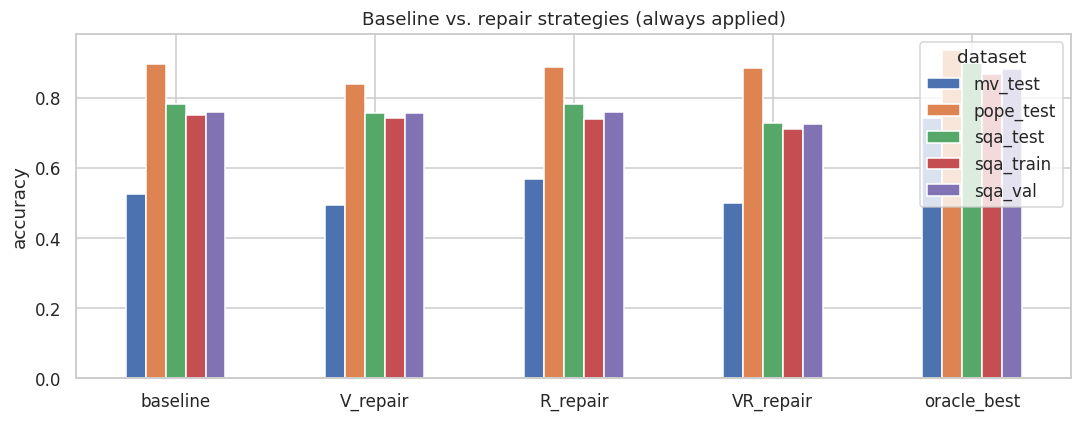

In [16]:
# PART-B
rows = []
for k, d in df.groupby("ds"):
    rows.append(dict(dataset=k, n=len(d), baseline=d.base_ok.mean(), V_repair=d.V_ok.mean(),
                     R_repair=d.R_ok.mean(), VR_repair=d.VR_ok.mean(),
                     oracle_best=(d.base_ok | d.V_ok | d.R_ok | d.VR_ok).mean()))
tab_acc = pd.DataFrame(rows).set_index("dataset")
display(tab_acc.round(3))
ax = tab_acc.drop(columns="n").T.plot(kind="bar", figsize=(10, 4)); ax.set_ylabel("accuracy"); ax.set_title("Baseline vs. repair strategies (always applied)")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(f"{RES}/fig_repair_accuracy.png"); plt.show()
tab_acc.round(4).to_csv(f"{RES}/table_repair_accuracy.csv")

### 4.2 Distribution of diagnosis labels

label,OK,PERC,REAS,MIXED,UNRES
ds,,,,,
mv_test,158,10,30,25,77
pope_test,269,4,6,2,19
sqa_test,235,3,17,15,30
sqa_train,902,38,54,50,156
sqa_val,228,7,17,13,35


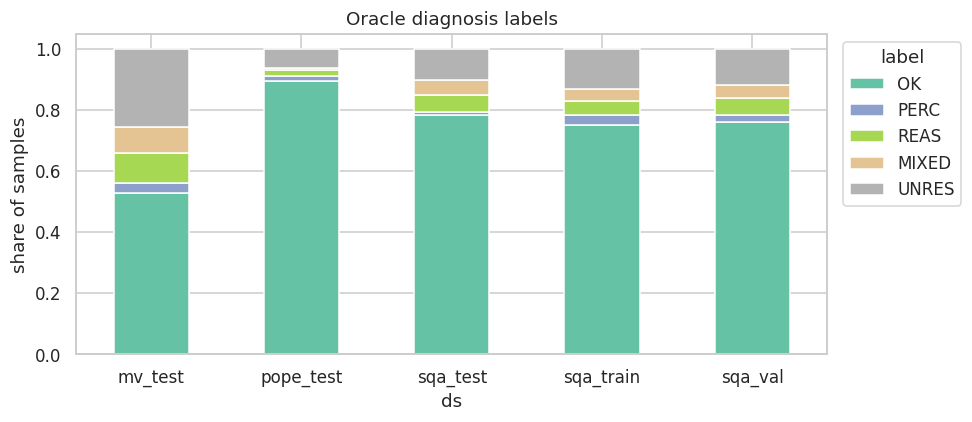

In [17]:
# PART-B
lab = pd.crosstab(df.ds, df.label).reindex(columns=CLASSES, fill_value=0)
display(lab)
lab_pct = lab.div(lab.sum(1), axis=0)
ax = lab_pct.plot(kind="bar", stacked=True, figsize=(9, 4), colormap="Set2"); ax.set_ylabel("share of samples"); ax.set_title("Oracle diagnosis labels")
plt.xticks(rotation=0); plt.legend(title="label", bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout()
plt.savefig(f"{RES}/fig_label_distribution.png"); plt.show()
lab.to_csv(f"{RES}/table_label_counts.csv")

### 4.3 Do the sensitivity signals actually separate the error types?
If the idea works, **PERC** samples should be more sensitive to visual probes (`s_v`) and **REAS** samples to textual probes (`s_r`).

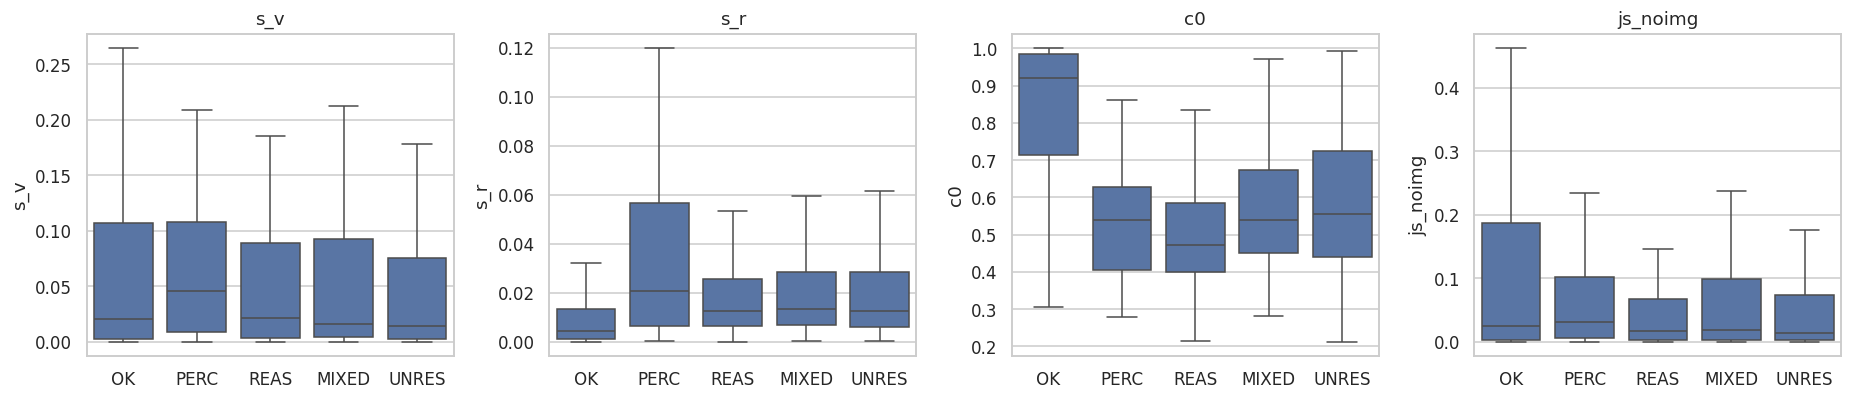

,feature,H,p
4,c0,685.2520,0.0000
6,margin,629.1797,0.0000
5,H0,546.9734,0.0000
3,g_r,403.4853,0.0000
10,js_shuf,286.8966,0.0000
1,s_r,246.5086,0.0000
11,js_para,85.7231,0.0000
8,js_crop,80.7353,0.0000
2,g_v,73.6304,0.0000
7,js_blur,22.1342,0.0002


In [18]:
# PART-B
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, f in zip(axes, ["s_v", "s_r", "c0", "js_noimg"]):
    sns.boxplot(data=df, x="label", y=f, order=CLASSES, ax=ax, showfliers=False)
    ax.set_title(f); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(f"{RES}/fig_signal_by_label.png"); plt.show()

from scipy.stats import kruskal
rows = []
for f in FEATS:
    g = [df.loc[df.label == c, f].values for c in CLASSES if (df.label == c).sum() > 2]
    if len(g) > 1:
        H, p = kruskal(*g); rows.append(dict(feature=f, H=H, p=p))
display(pd.DataFrame(rows).sort_values("p").round(4))

## 5. Train the router (ScienceQA-train → select on ScienceQA-val)
Candidates: logistic regression, random forest, gradient boosting, MLP. The best model by validation macro-F1 is selected, then temperature-scaled on validation, and a confidence threshold `tau` (below it the router falls back to UNRES = keep baseline and flag) is tuned on validation accuracy.

In [19]:
# PART-B
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report
from scipy.optimize import minimize_scalar
from scipy.special import softmax

def oversample(X, y, seed=0):
    rng = np.random.RandomState(seed); counts = pd.Series(y).value_counts(); m = counts.max(); idx = []
    for c in counts.index:
        ii = np.where(y == c)[0]; idx.extend(rng.choice(ii, m, replace=True))
    idx = np.array(idx); rng.shuffle(idx); return X[idx], y[idx]

def make_models(seed=0):
    ms = {
        "LogReg": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced")), False),
        "RandomForest": (RandomForestClassifier(300, min_samples_leaf=3, class_weight="balanced_subsample", random_state=seed, n_jobs=-1), False),
        "MLP": (make_pipeline(StandardScaler(), MLPClassifier((32, 16), alpha=1e-3, max_iter=800, early_stopping=False, random_state=seed)), True),
    }
    try:
        ms["HistGB"] = (HistGradientBoostingClassifier(class_weight="balanced", max_depth=4, learning_rate=0.06, random_state=seed), False)
    except TypeError:
        ms["HistGB"] = (HistGradientBoostingClassifier(max_depth=4, learning_rate=0.06, random_state=seed), True)
    return ms

def proba_full(est, X):
    P = est.predict_proba(X); out = np.zeros((len(X), len(CLASSES)))
    for j, c in enumerate(est.classes_): out[:, CLASSES.index(c)] = P[:, j]
    return out

def fit_router(trd, feats, seed=0, models=None):
    X, y = trd[feats].values, trd.label.values; fitted = {}
    for name, (est, need_os) in (models or make_models(seed)).items():
        Xf, yf = oversample(X, y, seed) if need_os else (X, y)
        est.fit(Xf, yf); fitted[name] = est
    return fitted

fitted = fit_router(tr, FEATS)
yv = va.label.values; sel = []
for name, est in fitted.items():
    P = proba_full(est, va[FEATS].values); pred = np.array(CLASSES)[P.argmax(1)]
    sel.append(dict(model=name, val_acc=accuracy_score(yv, pred), val_macroF1=f1_score(yv, pred, labels=CLASSES, average="macro", zero_division=0)))
sel = pd.DataFrame(sel).sort_values("val_macroF1", ascending=False); display(sel.round(3))
BEST = sel.iloc[0].model; router = fitted[BEST]; print("selected router:", BEST)
sel.round(4).to_csv(f"{RES}/table_router_selection.csv", index=False)

# temperature scaling on validation
def fit_temperature(P, yidx):
    L = np.log(np.clip(P, 1e-9, 1))
    def nll(T):
        Q = softmax(L / T, axis=1); return -np.mean(np.log(Q[np.arange(len(yidx)), yidx] + 1e-12))
    return float(minimize_scalar(nll, bounds=(0.2, 6), method="bounded").x)
def apply_T(P, T): return softmax(np.log(np.clip(P, 1e-9, 1)) / T, axis=1)

Pva = proba_full(router, va[FEATS].values); yv_idx = np.array([CLASSES.index(c) for c in yv])
TEMP = fit_temperature(Pva, yv_idx); print(f"temperature T = {TEMP:.3f}")

,model,val_acc,val_macroF1
2,MLP,0.623,0.334
1,RandomForest,0.680,0.318
3,HistGB,0.613,0.311
0,LogReg,0.543,0.301


selected router: MLP
temperature T = 6.000


### 5.1 Decision policy and evaluation helpers

In [20]:
# PART-B
def policy_pred(d, cls):
    cls = np.asarray(cls)
    return np.select([cls == "PERC", cls == "REAS", cls == "MIXED"],
                     [d.pV_pred.values, d.pR_pred.values, d.pVR_pred.values], default=d.p0_pred.values)

def policy_latency(d, cls, routed=True):
    cls = np.asarray(cls)
    extra = np.select([cls == "PERC", cls == "REAS", cls == "MIXED"], [d.t_V.values, d.t_R.values, d.t_VR.values], default=0.0)
    return d.t_base.values + (d.t_probe.values if routed else 0.0) + extra

def metrics(d, pred, lat=None):
    ok = pred == d.y.values; b = d.base_ok.values
    return dict(acc=ok.mean(), fix_rate=(ok[~b].mean() if (~b).any() else np.nan),
                harm_rate=((~ok)[b].mean() if b.any() else np.nan),
                intervention_rate=np.nan, latency_s=(np.mean(lat) if lat is not None else np.nan))

def route(P, tau):
    cls = np.array(CLASSES)[P.argmax(1)].astype(object); cls[P.max(1) < tau] = "UNRES"; return cls

def prcr_classes(d, est, T, tau, feats=FEATS):
    return route(apply_T(proba_full(est, d[feats].values), T), tau)

# tune tau on validation accuracy
taus = np.linspace(0, 0.8, 17); best = (-1, 0)
for t in taus:
    c = prcr_classes(va, router, TEMP, t); a = (policy_pred(va, c) == va.y.values).mean()
    if a > best[0] + 1e-9: best = (a, t)
TAU = float(best[1]); print(f"tau = {TAU:.2f}  (val acc {best[0]:.3f})")

# compute-matched confidence-gated baseline: intervene (V+R) on the same share of val samples as PRCR
c_val = prcr_classes(va, router, TEMP, TAU)
rate_val = float(np.isin(c_val, ["PERC", "REAS", "MIXED"]).mean())
TAU_G = float(np.quantile(va.c0.values, rate_val)) if rate_val > 0 else 0.0
print(f"intervention rate on val = {rate_val:.2%};  gated-baseline threshold c0 < {TAU_G:.3f}")

tau = 0.00  (val acc 0.790)
intervention rate on val = 18.00%;  gated-baseline threshold c0 < 0.542


## 6. Testing: PRCR vs. baselines
Methods: baseline VLM; always V-repair (self-captioning); always R-repair (step-by-step reasoning); always V+R; confidence-gated V+R (compute-matched adaptive-routing baseline); **PRCR (ours)**; and the oracle router (upper bound, uses ground truth).

In [21]:
# PART-B
def eval_all(d, est=router, T=TEMP, tau=TAU, feats=FEATS):
    out = {}
    n = len(d); ok = lambda p: p == d.y.values
    out["Baseline VLM"]                 = (d.p0_pred.values,  d.t_base.values, 0.0)
    out["Always V-repair (self-caption)"] = (d.pV_pred.values,  d.t_base.values + d.t_V.values, 1.0)
    out["Always R-repair (step-by-step)"] = (d.pR_pred.values,  d.t_base.values + d.t_R.values, 1.0)
    out["Always V+R"]                   = (d.pVR_pred.values, d.t_base.values + d.t_VR.values, 1.0)
    g = d.c0.values < TAU_G
    out["Conf-gated V+R (adaptive baseline)"] = (np.where(g, d.pVR_pred.values, d.p0_pred.values), d.t_base.values + g * d.t_VR.values, g.mean())
    c = prcr_classes(d, est, T, tau, feats)
    out["PRCR (ours)"] = (policy_pred(d, c), policy_latency(d, c, True), np.isin(c, ["PERC", "REAS", "MIXED"]).mean())
    co = d.label.values
    out["Oracle router (upper bound)"] = (policy_pred(d, co), policy_latency(d, co, False), np.isin(co, ["PERC", "REAS", "MIXED"]).mean())
    rows = []
    for name, (pred, lat, ir) in out.items():
        m = metrics(d, pred, lat); m["intervention_rate"] = ir; m["method"] = name; rows.append(m)
    return pd.DataFrame(rows).set_index("method"), c

results, routed_cls = {}, {}
for k in TEST_SETS:
    if len(te[k]) == 0: continue
    results[k], routed_cls[k] = eval_all(te[k])
    print(f"\n=== {PRETTY[k]}  (n={len(te[k])}) ===")
    display(results[k].round(3))

main = pd.concat({PRETTY[k]: v["acc"] for k, v in results.items()}, axis=1)
display(main.round(3))
main.round(4).to_csv(f"{RES}/table_main_accuracy.csv")
for k, v in results.items(): v.round(4).to_csv(f"{RES}/table_full_{k}.csv")


=== ScienceQA (in-domain)  (n=300) ===


,acc,fix_rate,harm_rate,intervention_rate,latency_s
method,,,,,
Baseline VLM,0.783,0.000,0.000,0.000,0.167
Always V-repair (self-caption),0.757,0.108,0.064,1.000,3.740
Always R-repair (step-by-step),0.783,0.323,0.089,1.000,1.954
Always V+R,0.730,0.308,0.153,1.000,6.937
Conf-gated V+R (adaptive baseline),0.790,0.185,0.043,0.193,1.641
PRCR (ours),0.790,0.123,0.026,0.163,1.638
Oracle router (upper bound),0.897,0.523,0.000,0.117,0.709



=== POPE  (n=300) ===


,acc,fix_rate,harm_rate,intervention_rate,latency_s
method,,,,,
Baseline VLM,0.897,0.000,0.000,0.000,0.224
Always V-repair (self-caption),0.840,0.129,0.078,1.000,3.920
Always R-repair (step-by-step),0.890,0.194,0.030,1.000,0.695
Always V+R,0.887,0.194,0.033,1.000,4.314
Conf-gated V+R (adaptive baseline),0.890,0.000,0.007,0.013,0.285
PRCR (ours),0.867,0.032,0.037,0.073,1.427
Oracle router (upper bound),0.937,0.387,0.000,0.040,0.309



=== MathVista-MC  (n=300) ===


,acc,fix_rate,harm_rate,intervention_rate,latency_s
method,,,,,
Baseline VLM,0.527,0.000,0.000,0.000,0.173
Always V-repair (self-caption),0.493,0.141,0.190,1.000,3.760
Always R-repair (step-by-step),0.570,0.282,0.171,1.000,2.496
Always V+R,0.500,0.268,0.291,1.000,7.049
Conf-gated V+R (adaptive baseline),0.560,0.197,0.114,0.533,4.241
PRCR (ours),0.527,0.106,0.095,0.357,2.608
Oracle router (upper bound),0.737,0.444,0.000,0.217,1.201


,ScienceQA (in-domain),POPE,MathVista-MC
method,,,
Baseline VLM,0.783,0.897,0.527
Always V-repair (self-caption),0.757,0.840,0.493
Always R-repair (step-by-step),0.783,0.890,0.570
Always V+R,0.730,0.887,0.500
Conf-gated V+R (adaptive baseline),0.790,0.890,0.560
PRCR (ours),0.790,0.867,0.527
Oracle router (upper bound),0.897,0.937,0.737


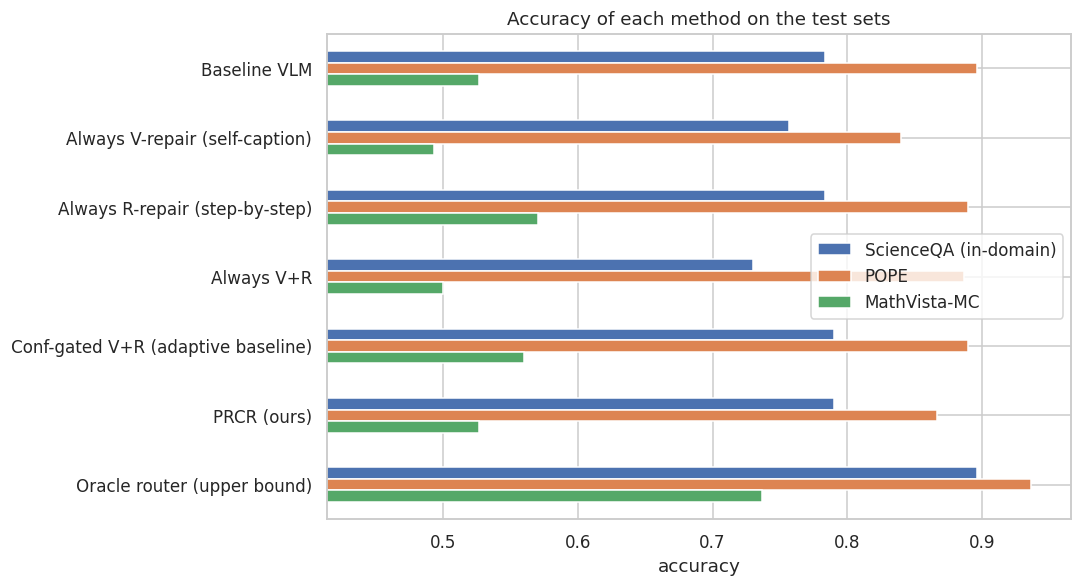

ScienceQA (in-domain)               POPE  \
                                                fix_rate harm_rate fix_rate   
method                                                                        
Baseline VLM                                       0.000     0.000    0.000   
Always V-repair (self-caption)                     0.108     0.064    0.129   
Always R-repair (step-by-step)                     0.323     0.089    0.194   
Always V+R                                         0.308     0.153    0.194   
Conf-gated V+R (adaptive baseline)                 0.185     0.043    0.000   
PRCR (ours)                                        0.123     0.026    0.032   
Oracle router (upper bound)                        0.523     0.000    0.387   

                                             MathVista-MC            
                                   harm_rate     fix_rate harm_rate  
method                                                               
Baseline VLM                           0.000        0.000     0.000  
Always V-repair (self-caption)         0.078        0.141     0.190  
Always R-repair (step-by-step)         0.030        0.282     0.171  
Always V+R                             0.033        0.268     0.291  
Conf-gated V+R (adaptive baseline)     0.007        0.197     0.114  
PRCR (ours)                            0.037        0.106     0.095  
Oracle router (upper bound)            0.000        0.444     0.000

In [22]:
# PART-B
ax = main.plot(kind="barh", figsize=(10, 5.5)); ax.set_xlabel("accuracy"); ax.set_ylabel(""); ax.invert_yaxis()
ax.set_title("Accuracy of each method on the test sets"); lo = max(0, main.min().min() - 0.08); ax.set_xlim(lo, min(1.0, main.max().max() + 0.03))
plt.tight_layout(); plt.savefig(f"{RES}/fig_main_accuracy.png"); plt.show()

# fix / harm
fh = pd.concat({PRETTY[k]: v[["fix_rate", "harm_rate"]] for k, v in results.items()}, axis=1)
display(fh.round(3)); fh.round(4).to_csv(f"{RES}/table_fix_harm.csv")

### 6.1 Accuracy–latency trade-off
PRCR pays for 5 probe passes on every sample, then only the repair it needs. The scatter shows whether that is cheaper than always repairing.

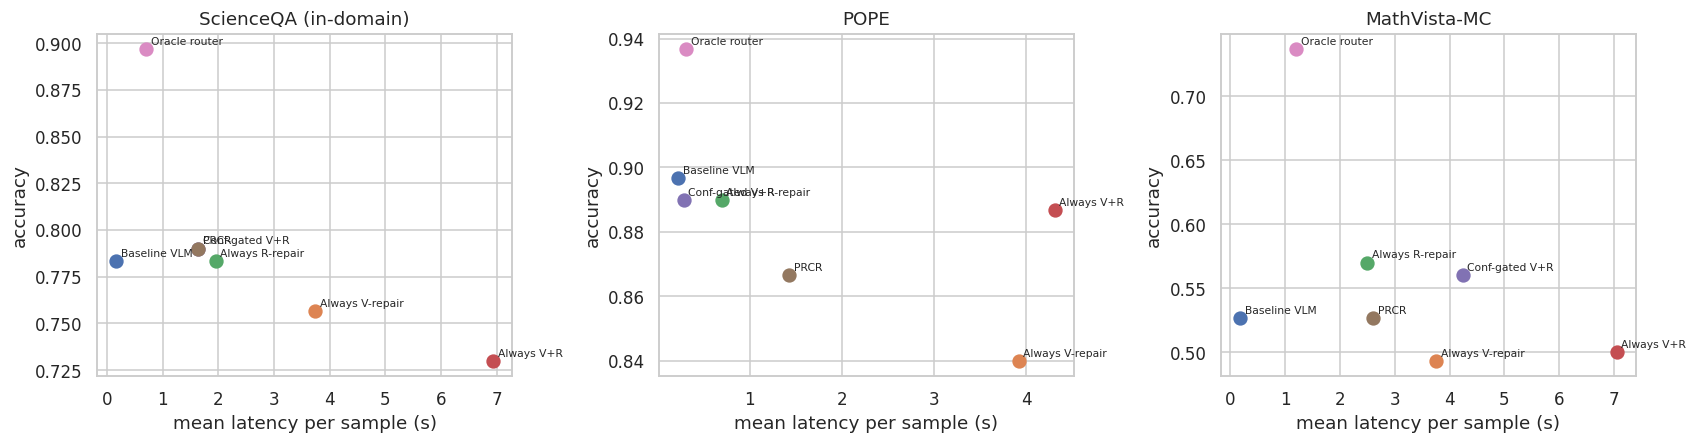

In [23]:
# PART-B
fig, axes = plt.subplots(1, len(results), figsize=(5.2 * len(results), 4.2), squeeze=False)
for ax, (k, v) in zip(axes[0], results.items()):
    for name, r in v.iterrows():
        if np.isnan(r.latency_s): continue
        ax.scatter(r.latency_s, r.acc, s=70, label=name if k == list(results)[0] else None)
        ax.annotate(name.split(" (")[0][:16], (r.latency_s, r.acc), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.set_title(PRETTY[k]); ax.set_xlabel("mean latency per sample (s)"); ax.set_ylabel("accuracy")
plt.tight_layout(); plt.savefig(f"{RES}/fig_accuracy_latency.png"); plt.show()

## 7. How good is the diagnosis itself?
Compares the router's predicted state with the oracle label on the test sets (5 classes).

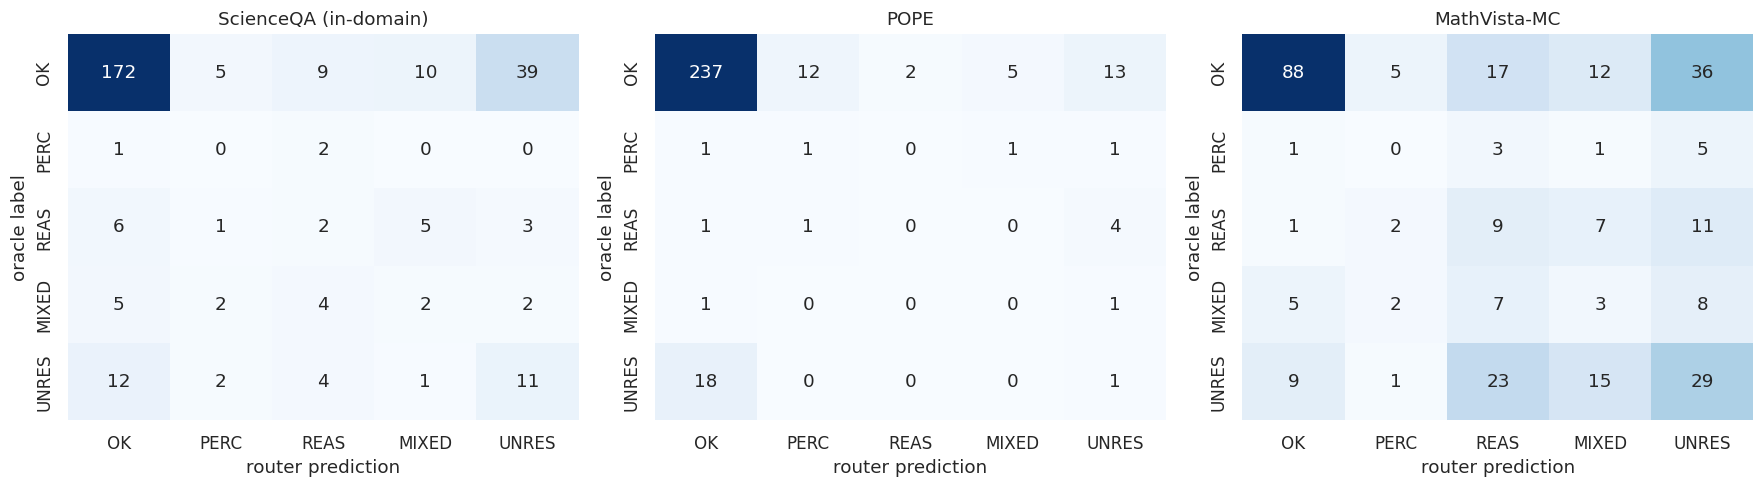

,accuracy,macro_F1,weighted_F1
dataset,,,
ScienceQA (in-domain),0.623,0.257,0.663
POPE,0.797,0.212,0.811
MathVista-MC,0.430,0.264,0.472


              precision    recall  f1-score   support

          OK       0.89      0.75      0.81       662
        PERC       0.03      0.06      0.04        17
        REAS       0.13      0.21      0.16        53
       MIXED       0.08      0.12      0.10        42
       UNRES       0.25      0.33      0.28       126

    accuracy                           0.62       900
   macro avg       0.28      0.29      0.28       900
weighted avg       0.70      0.62      0.65       900



In [24]:
# PART-B
diag = []
fig, axes = plt.subplots(1, len(routed_cls), figsize=(5.4 * len(routed_cls), 4.6), squeeze=False)
for ax, (k, c) in zip(axes[0], routed_cls.items()):
    y = te[k].label.values
    cm = confusion_matrix(y, c, labels=CLASSES)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax, cbar=False)
    ax.set_title(f"{PRETTY[k]}"); ax.set_xlabel("router prediction"); ax.set_ylabel("oracle label")
    diag.append(dict(dataset=PRETTY[k], accuracy=accuracy_score(y, c),
                     macro_F1=f1_score(y, c, labels=CLASSES, average="macro", zero_division=0),
                     weighted_F1=f1_score(y, c, labels=CLASSES, average="weighted", zero_division=0)))
plt.tight_layout(); plt.savefig(f"{RES}/fig_confusion_matrices.png"); plt.show()
diag = pd.DataFrame(diag).set_index("dataset"); display(diag.round(3)); diag.round(4).to_csv(f"{RES}/table_diagnosis_metrics.csv")

pooled_y = np.concatenate([te[k].label.values for k in routed_cls]); pooled_c = np.concatenate(list(routed_cls.values()))
print(classification_report(pooled_y, pooled_c, labels=CLASSES, zero_division=0))

### 7.1 Calibration of the router (reliability diagram and ECE)

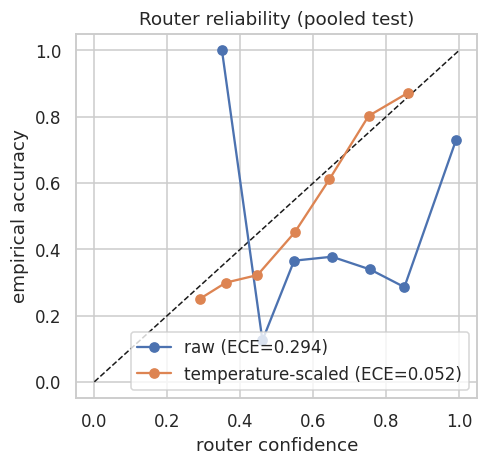

In [25]:
# PART-B
def ece_curve(conf, correct, bins=10):
    edges = np.linspace(0, 1, bins + 1); xs, ys, e = [], [], 0.0
    for i in range(bins):
        m = (conf > edges[i]) & (conf <= edges[i + 1])
        if m.sum() == 0: continue
        xs.append(conf[m].mean()); ys.append(correct[m].mean()); e += m.mean() * abs(conf[m].mean() - correct[m].mean())
    return xs, ys, e

pool = pd.concat(te.values(), ignore_index=True)
P_raw = proba_full(router, pool[FEATS].values); P_cal = apply_T(P_raw, TEMP)
yp = np.array([CLASSES.index(c) for c in pool.label.values])
fig, ax = plt.subplots(figsize=(4.6, 4.4)); ax.plot([0, 1], [0, 1], "k--", lw=1)
for nm, P in [("raw", P_raw), ("temperature-scaled", P_cal)]:
    xs, ys, e = ece_curve(P.max(1), (P.argmax(1) == yp).astype(float)); ax.plot(xs, ys, "o-", label=f"{nm} (ECE={e:.3f})")
ax.set_xlabel("router confidence"); ax.set_ylabel("empirical accuracy"); ax.legend(); ax.set_title("Router reliability (pooled test)")
plt.tight_layout(); plt.savefig(f"{RES}/fig_router_reliability.png"); plt.show()

## 8. Which signals matter? (feature importance and ablations)

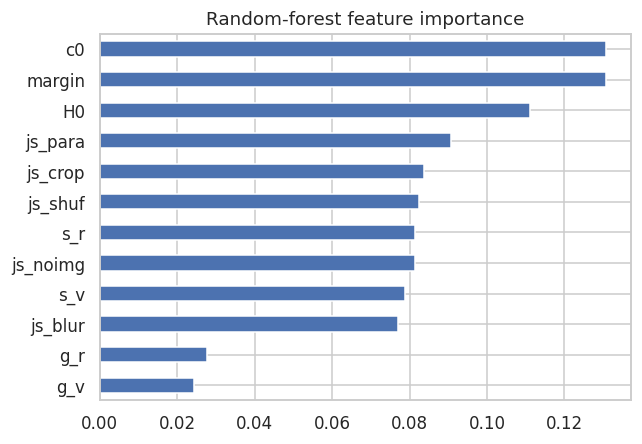

,ScienceQA (in-domain) acc,POPE acc,MathVista-MC acc,mean acc,mean diag macro-F1
variant,,,,,
Full (all 12 features),0.790,0.867,0.527,0.728,0.244
Visual probes only,0.790,0.897,0.543,0.743,0.269
Textual probes only,0.787,0.883,0.563,0.744,0.274
Confidence only,0.787,0.893,0.520,0.733,0.285
No confidence features,0.793,0.890,0.513,0.732,0.248


In [26]:
# PART-B
rf = fitted["RandomForest"]
imp = pd.Series(rf.feature_importances_, index=FEATS).sort_values()
ax = imp.plot(kind="barh", figsize=(6, 4.2)); ax.set_title("Random-forest feature importance"); plt.tight_layout()
plt.savefig(f"{RES}/fig_feature_importance.png"); plt.show()

ABL = {"Full (all 12 features)": FEATS, "Visual probes only": F_VISUAL + F_CONF, "Textual probes only": F_TEXT + F_CONF,
       "Confidence only": F_CONF, "No confidence features": F_VISUAL + F_TEXT}
rows = []
for nm, fs in ABL.items():
    est = fit_router(tr, fs, models={BEST: make_models()[BEST]})[BEST]
    Pv = proba_full(est, va[fs].values); T = fit_temperature(Pv, yv_idx)
    row = dict(variant=nm)
    accs, f1s = [], []
    for k in TEST_SETS:
        if len(te[k]) == 0: continue
        c = prcr_classes(te[k], est, T, TAU, fs); a = (policy_pred(te[k], c) == te[k].y.values).mean()
        row[PRETTY[k] + " acc"] = a; accs.append(a)
        f1s.append(f1_score(te[k].label.values, c, labels=CLASSES, average="macro", zero_division=0))
    row["mean acc"] = np.mean(accs); row["mean diag macro-F1"] = np.mean(f1s); rows.append(row)
abl = pd.DataFrame(rows).set_index("variant"); display(abl.round(3)); abl.round(4).to_csv(f"{RES}/table_ablation.csv")

## 9. Statistical reliability
Paired bootstrap (2,000 resamples) of the accuracy gain of PRCR over the baseline VLM and over the compute-matched gated baseline.

In [27]:
# PART-B
def boot(a, b, B=2000, seed=0):
    rng = np.random.RandomState(seed); n = len(a); d = []
    for _ in range(B):
        ix = rng.randint(0, n, n); d.append(a[ix].mean() - b[ix].mean())
    return float(np.mean(d)), float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))

rows = []
for k in TEST_SETS:
    d = te[k]
    if len(d) == 0: continue
    c = routed_cls[k]; prcr_ok = (policy_pred(d, c) == d.y.values).astype(float)
    base_ok = d.base_ok.values.astype(float)
    g = d.c0.values < TAU_G; gated_ok = (np.where(g, d.pVR_pred.values, d.p0_pred.values) == d.y.values).astype(float)
    for ref, arr in [("Baseline VLM", base_ok), ("Conf-gated V+R", gated_ok)]:
        m, lo, hi = boot(prcr_ok, arr); rows.append(dict(dataset=PRETTY[k], vs=ref, mean_gain=m, ci95_low=lo, ci95_high=hi, significant=(lo > 0 or hi < 0)))
boot_tab = pd.DataFrame(rows); display(boot_tab.round(4)); boot_tab.round(4).to_csv(f"{RES}/table_bootstrap.csv", index=False)

,dataset,vs,mean_gain,ci95_low,ci95_high,significant
0,ScienceQA (in-domain),Baseline VLM,0.0067,-0.0167,0.0300,False
1,ScienceQA (in-domain),Conf-gated V+R,-0.0002,-0.0300,0.0300,False
2,POPE,Baseline VLM,-0.0302,-0.0533,-0.0100,True
3,POPE,Conf-gated V+R,-0.0235,-0.0434,-0.0067,True
4,MathVista-MC,Baseline VLM,-0.0002,-0.0367,0.0367,False
5,MathVista-MC,Conf-gated V+R,-0.0335,-0.0800,0.0100,False


## 10. Qualitative examples
A few samples per diagnosis class, with the baseline, repair predictions and the model's own caption and rationale.

In [28]:
# PART-B
ex = pd.concat(te.values(), ignore_index=True)
for c in ["PERC", "REAS", "MIXED", "UNRES"]:
    sub = ex[ex.label == c].head(2)
    print("=" * 100); print(f"LABEL = {c}   (count in test: {(ex.label == c).sum()})")
    for _, r in sub.iterrows():
        print(f"- [{r.ds}] Q: {r.q}")
        print(f"  gold={r.y} base={r.p0_pred} V={r.pV_pred} R={r.pR_pred} VR={r.pVR_pred} | s_v={r.s_v:.2f} s_r={r.s_r:.2f} c0={r.c0:.2f}")
        print(f"  caption  : {r.cap[:160]}"); print(f"  rationale: {r.rat[:160]}")

LABEL = PERC   (count in test: 17)
- [sqa_test] Q: What is the probability that a Syrian hamster produced by this cross will have long fur? Context: In a group of Syrian hamsters, some individuals have short fur
  gold=0 base=1 V=0 R=1 VR=4 | s_v=0.04 s_r=0.05 c0=0.37
  caption  : The image is a 2x2 grid, consisting of four squares, each containing a different genotype. The grid is divided into two rows and two columns, with each cell con
  rationale: To determine the probability that a Syrian hamster produced by this cross will have long fur, we need to analyze the Punnett square provided.

1. The Punnett sq
- [sqa_test] Q: Which term matches the picture? Context: Read the text. Filtration and centrifugation are two techniques used to separate different materials from a mixture. Fi
  gold=0 base=1 V=0 R=1 VR=0 | s_v=0.00 s_r=0.04 c0=0.69
  caption  : The image depicts a laboratory setting where several beakers and flasks are arranged on a table. The beakers and flasks are made of glas

## 11. Export tables, LaTeX and figures for the paper

In [29]:
# PART-B
import zipfile
def tex(df_, name, cap, label, fmt="%.3f"):
    try:
        s = df_.to_latex(float_format=fmt, caption=cap, label=label, escape=True)
        open(f"{RES}/{name}.tex", "w").write(s); print("wrote", name + ".tex")
    except Exception as e:
        print("latex export skipped:", repr(e)[:80])

tex(main, "tab_main_accuracy", "Accuracy of PRCR and baselines on the test sets.", "tab:main_acc")
tex(abl, "tab_ablation", "Ablation of the signal groups used by the router.", "tab:ablation")
tex(diag, "tab_diagnosis", "Diagnosis quality of the router against the oracle labels.", "tab:diagnosis")
tex(fh, "tab_fix_harm", "Fix rate and harm rate of each method.", "tab:fixharm")

summary = {"router": BEST, "temperature": TEMP, "tau": TAU, "gated_threshold": TAU_G,
           "n_train": int(len(tr)), "n_val": int(len(va)), "n_test": {k: int(len(v)) for k, v in te.items()},
           "main_accuracy": main.round(4).to_dict()}
json.dump(summary, open(f"{RES}/summary.json", "w"), indent=1)
with zipfile.ZipFile(f"{WORK}/prcr_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in glob.glob(f"{RES}/*"): z.write(f, os.path.basename(f))
print("saved ->", f"{WORK}/prcr_results.zip"); print(sorted(os.listdir(RES)))

wrote tab_main_accuracy.tex
wrote tab_ablation.tex
wrote tab_diagnosis.tex
wrote tab_fix_harm.tex
saved -> /kaggle/working/prcr_results.zip
['fig_accuracy_latency.png', 'fig_confusion_matrices.png', 'fig_feature_importance.png', 'fig_label_distribution.png', 'fig_main_accuracy.png', 'fig_repair_accuracy.png', 'fig_router_reliability.png', 'fig_signal_by_label.png', 'summary.json', 'tab_ablation.tex', 'tab_diagnosis.tex', 'tab_fix_harm.tex', 'tab_main_accuracy.tex', 'table_ablation.csv', 'table_bootstrap.csv', 'table_diagnosis_metrics.csv', 'table_fix_harm.csv', 'table_full_mv_test.csv', 'table_full_pope_test.csv', 'table_full_sqa_test.csv', 'table_label_counts.csv', 'table_main_accuracy.csv', 'table_repair_accuracy.csv', 'table_router_selection.csv']


## 12. How to use these results in the paper
- **Main result:** `table_main_accuracy` and `fig_main_accuracy` (PRCR vs. baselines on ScienceQA, POPE, MathVista).
- **Does diagnosis work?** `fig_signal_by_label`, `fig_confusion_matrices`, `table_diagnosis_metrics`.
- **Which signals matter?** `fig_feature_importance`, `table_ablation`.
- **Cost:** `fig_accuracy_latency` and the `latency_s` column of `table_full_*`.
- **Safety:** `table_fix_harm` (harm rate = correct answers broken by an intervention).
- **Reliability:** `table_bootstrap` (95% confidence intervals) and `fig_router_reliability`.

**Limitations to state honestly**
- Oracle labels depend on the repairs we chose (caption, step-by-step, both) and on one backbone (Qwen2-VL-2B).
- Options are scored by letter logits, so results are for multiple-choice style evaluation.
- Subsets are small. For the final paper, raise `N_*`, add seeds (change `CFG["SEED"]`) and report mean ± std.
- Test sets are never used for training. If you change the router, re-select it on validation only.